<a href="https://colab.research.google.com/github/Niha5019/MLA0201-FOML/blob/main/EXP4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANN Predictions:
[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 0


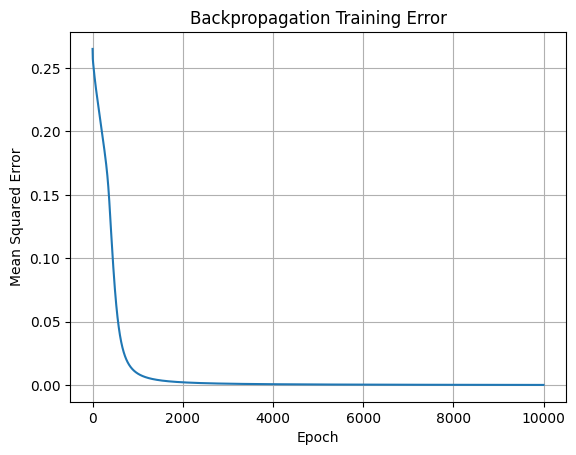

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# XOR dataset
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

np.random.seed(1)

# Initialize weights and biases
W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

errors = []
lr = 0.5

# Backpropagation training
for epoch in range(10000):
    h = sigmoid(X @ W1 + b1)
    out = sigmoid(h @ W2 + b2)

    error = y - out
    errors.append(np.mean(error ** 2))

    d_out = error * out * (1 - out)
    d_h = (d_out @ W2.T) * h * (1 - h)

    W2 += lr * h.T @ d_out
    b2 += lr * np.sum(d_out, axis=0, keepdims=True)
    W1 += lr * X.T @ d_h
    b1 += lr * np.sum(d_h, axis=0, keepdims=True)

# Test network
print("ANN Predictions:")
for i in range(len(X)):
    prediction = int(out[i, 0] >= 0.5)
    print(X[i], "->", prediction)

# Plot error graph
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Backpropagation Training Error")
plt.grid(True)
plt.show()